<a href="https://colab.research.google.com/github/Hithavan31/AI_LAB_PROGRAMS/blob/main/1BM24CS118_WEEK10_Alpha_beta_Pruning_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Alpha-Beta Pruning (root = MAX, levels alternate MAX/MIN)
Choose: 1-4 = sample problems from slides, or 0 = enter your own tree
Choice: 0
Enter tree as nested lists, e.g. [[[10,9],[14,18]],[[5,4],[50,3]]]
Tree:  [[[2, 3], [5, 9]], [[0, 1], [7, 5]]]

--- Execution trace ---
 visit leaf R.1.1.1: value = 2
 visit leaf R.1.1.2: value = 3
 MAX R.1.1 = 3 (alpha=3, beta=inf)
 visit leaf R.1.2.1: value = 5
 PRUNE at MAX R.1.2: v=5 >= beta=3; skipping 1 remaining branch(es)
 MAX R.1.2 = 5 (alpha=-inf, beta=3)
 MIN R.1 = 3 (alpha=-inf, beta=3)
 visit leaf R.2.1.1: value = 0
 visit leaf R.2.1.2: value = 1
 MAX R.2.1 = 1 (alpha=3, beta=inf)
 PRUNE at MIN R.2: v=1 <= alpha=3; skipping 1 remaining branch(es)
 MIN R.2 = 1 (alpha=3, beta=inf)
 MAX R = 3 (alpha=3, beta=inf)

--- Result ---
Root (MAX) value : 3
Optimal path : R(3) -> R.1(3) -> R.1.1(3) -> R.1.1.2(3)
Pruned branches : R.1.2.2, R.2.2

Graph saved to alpha_beta_tree.png


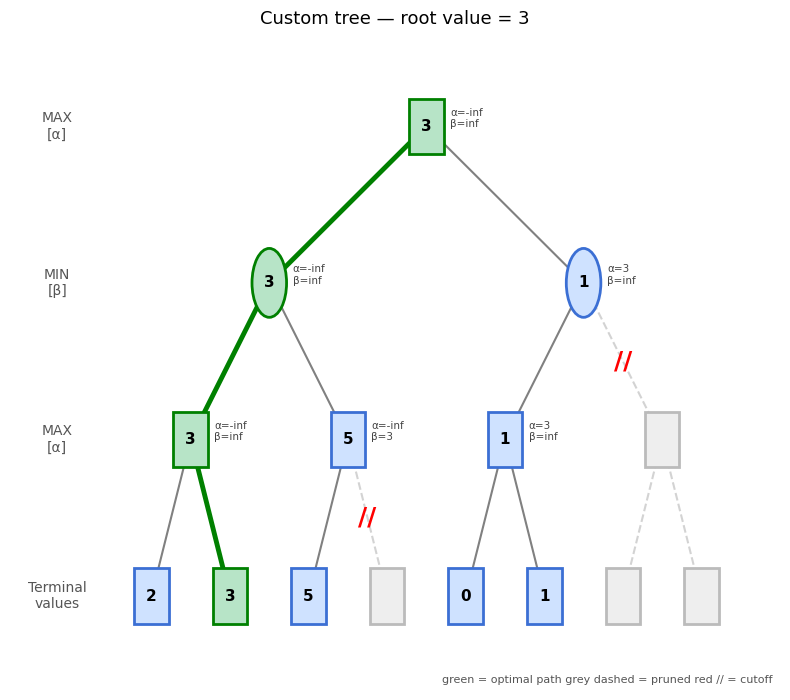

In [2]:
"""
Alpha-Beta Pruning with user input and graph output.

Tree input = nested Python lists. Root is a MAX node, levels alternate MAX/MIN.
Leaves are numbers. Example (Problem 1): [[[10,9],[14,18]],[[5,4],[50,3]]]
"""
import ast
import math
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

SAMPLES = {
    "1": ("Problem 1", [[[10, 9], [14, 18]], [[5, 4], [50, 3]]]),
    "2": ("Problem 2", [[[[5, 6], [7, 4, 5]], [[3]]],
                        [[[6], [6, 9]], [[7]]],
                        [[[5]], [[9, 8], [6]]]]),
    "3": ("Problem 3", ),
    "4": ("Problem 4", [[[[21, 5], [15, 11]], [[12, 8], [9, 13]]],
                        [[[5, 12], [13, 12]], [[13, 14], [7, 10]]]]),
}


class Node:
    def __init__(self, data, depth, name):
        self.depth = depth
        self.name = name
        self.is_max = depth % 2 == 0
        self.children = []
        self.value = None # computed value (None -> never evaluated)
        self.visited = False
        self.pruned_after = None # index of child after which cutoff happened
        self.best = None # child giving the node's value
        self.alpha = self.beta = None
        self.x = self.y = 0
        if isinstance(data, list):
            self.leaf = False
            for i, c in enumerate(data):
                self.children.append(Node(c, depth + 1, f"{name}.{i + 1}"))
        else:
            self.leaf = True
            self.value = data


def alpha_beta(node, alpha, beta, log):
    node.visited = True
    node.alpha, node.beta = alpha, beta
    if node.leaf:
        log.append(f" visit leaf {node.name}: value = {node.value}")
        return node.value
    v = -math.inf if node.is_max else math.inf
    kind = "MAX" if node.is_max else "MIN"
    for i, ch in enumerate(node.children):
        cv = alpha_beta(ch, alpha, beta, log)
        if node.is_max:
            if cv > v:
                v, node.best = cv, ch
            if v >= beta:
                node.pruned_after = i
                rest = len(node.children) - i - 1
                if rest:
                    log.append(f" PRUNE at {kind} {node.name}: v={v} >= beta={beta}; "
                               f"skipping {rest} remaining branch(es)")
                break
            alpha = max(alpha, v)
        else:
            if cv < v:
                v, node.best = cv, ch
            if v <= alpha:
                node.pruned_after = i
                rest = len(node.children) - i - 1
                if rest:
                    log.append(f" PRUNE at {kind} {node.name}: v={v} <= alpha={alpha}; "
                               f"skipping {rest} remaining branch(es)")
                break
            beta = min(beta, v)
    node.value = v
    log.append(f" {kind} {node.name} = {v} (alpha={alpha}, beta={beta})")
    return v


def layout(node, counter):
    node.y = -node.depth
    if node.leaf:
        node.x = counter[0]
        counter[0] += 1
    else:
        for c in node.children:
            layout(c, counter)
        node.x = sum(c.x for c in node.children) / len(node.children)


def all_nodes(node):
    yield node
    for c in node.children:
        yield from all_nodes(c)


def optimal_path(root):
    path, n = [root], root
    while n.best is not None:
        n = n.best
        path.append(n)
    return path


def draw(root, title, filename):
    layout(root, [0])
    nodes = list(all_nodes(root))
    path = set(id(n) for n in optimal_path(root))
    maxd = max(n.depth for n in nodes)
    width = max(8, (sum(1 for n in nodes if n.leaf)) * 0.9)
    fig, ax = plt.subplots(figsize=(width, 2 + 1.7 * maxd))

    # edges
    for n in nodes:
        for i, c in enumerate(n.children):
            cut = not c.visited
            on_path = id(n) in path and id(c) in path
            ax.plot([n.x, c.x], [n.y, c.y],
                    color="green" if on_path else ("lightgray" if cut else "gray"),
                    lw=3.5 if on_path else 1.5,
                    ls="--" if cut else "-", zorder=1)
            if cut and n.visited and n.pruned_after is not None \
                    and i == n.pruned_after + 1:
                mx, my = (n.x + c.x) / 2, (n.y + c.y) / 2
                ax.text(mx, my, "//", color="red", fontsize=18,
                        fontweight="bold", ha="center", va="center", zorder=4)

    # nodes
    r = 0.22
    for n in nodes:
        if not n.visited:
            fc, ec = "#eeeeee", "#bbbbbb"
        elif id(n) in path:
            fc, ec = "#b7e4c7", "green"
        else:
            fc, ec = "#cfe2ff", "#3b6fd4"
        if n.is_max and not n.leaf or (n.leaf and n.depth % 2 == 0):
            ax.add_patch(Rectangle((n.x - r, n.y - r * 0.8), 2 * r, 1.6 * r,
                                   fc=fc, ec=ec, lw=2, zorder=2))
        elif n.leaf:
            ax.add_patch(Rectangle((n.x - r, n.y - r * 0.8), 2 * r, 1.6 * r,
                                   fc=fc, ec=ec, lw=2, zorder=2))
        else:
            ax.add_patch(Circle((n.x, n.y), r, fc=fc, ec=ec, lw=2, zorder=2))
        label = "" if (n.value is None or not n.visited) else str(n.value)
        if label.endswith(".0"):
            label = label[:-2]
        ax.text(n.x, n.y, label, ha="center", va="center", fontsize=11,
                fontweight="bold", zorder=3)
        if n.visited and not n.leaf:
            a = "-inf" if n.alpha == -math.inf else n.alpha
            b = "inf" if n.beta == math.inf else n.beta
            ax.text(n.x + r + 0.08, n.y + 0.05, f"α={a}\nβ={b}", fontsize=7.5,
                    color="#444", va="center", zorder=3)

    for d in range(maxd + 1):
        lab = "MAX" if d % 2 == 0 else "MIN"
        txt = f"{lab}\n{'[α]' if lab == 'MAX' else '[β]'}"
        if all(n.leaf for n in nodes if n.depth == d):
            txt = "Terminal\nvalues"
        ax.text(-1.2, -d, txt,
                ha="center", va="center", fontsize=10, color="#555")

    ax.text(0.99, 0.01,
            "green = optimal path grey dashed = pruned red // = cutoff",
            transform=ax.transAxes, ha="right", fontsize=8, color="#555")
    ax.set_title(f"{title} — root value = {root.value}", fontsize=13)
    ax.set_xlim(-1.8, max(n.x for n in nodes) + 1)
    ax.set_ylim(-maxd - 0.6, 0.6)
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    print(f"\nGraph saved to {filename}")
    try:
        plt.show()
    except Exception:
        pass


def read_tree():
    print("Alpha-Beta Pruning (root = MAX, levels alternate MAX/MIN)")
    print("Choose: 1-4 = sample problems from slides, or 0 = enter your own tree")
    ch = input("Choice: ").strip()
    if ch in SAMPLES:
        return SAMPLES[ch]
    print("Enter tree as nested lists, e.g. [[[10,9],[14,18]],[[5,4],[50,3]]]")
    while True:
        try:
            t = ast.literal_eval(input("Tree: ").strip())
            if isinstance(t, list):
                return "Custom tree", t
        except Exception:
            pass
        print("Invalid input, try again.")


def main():
    title, data = read_tree()
    root = Node(data, 0, "R")
    log = []
    print("\n--- Execution trace ---")
    value = alpha_beta(root, -math.inf, math.inf, log)
    print("\n".join(log))

    path = optimal_path(root)
    print("\n--- Result ---")
    print("Root (MAX) value :", value)
    print("Optimal path :", " -> ".join(
        f"{n.name}({n.value})" for n in path))
    pruned = [n.name for n in all_nodes(root)
              if not n.visited and
              (n is root or next((p for p in all_nodes(root)
                                  if n in p.children), None).visited)]
    print("Pruned branches :", ", ".join(pruned) if pruned else "None")
    draw(root, title, "alpha_beta_tree.png")


if __name__ == "__main__":
    main()

